# Deep Learning, Phase 2 (CNNs), Day 2: A CNN in PyTorch vs an MLP on Fashion-MNIST
Yesterday we coded convolution by hand. Today we use PyTorch's `nn.Conv2d` and `nn.MaxPool2d`, train on the **GPU**, and check whether a CNN really beats the MLP from Phase 1 on images.
1. GPU and data  2. Baseline MLP  3. Building a CNN and tracking shapes  4. Training both  5. Comparison  6. Looking at predictions



In [1]:
import time, numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import torch, torch.nn as nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
sns.set_theme(style='whitegrid')

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Using device:', device)
if device == 'cpu': print('WARNING: no GPU found. Training will be slow. Runtime > Change runtime type > T4 GPU.')
torch.manual_seed(0); np.random.seed(0)

Using device: cuda


## 1. Data: Fashion-MNIST
70,000 grayscale 28x28 images of clothing in 10 classes (T-shirt, trouser, pullover, dress, coat, sandal, shirt, sneaker, bag, ankle boot). 60,000 for training and 10,000 for testing. It downloads automatically.

- `ToTensor()` turns an image into a tensor of shape **(1, 28, 28)** with values 0 to 1.
- `Normalize(mean, std)` standardises the pixel values (like `StandardScaler` for images). We use the mean and std of the training set.
- We keep 5,000 training images as a **validation set**. The **test set stays locked until Day 3.**

100%|██████████| 26.4M/26.4M [00:02<00:00, 12.8MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 203kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.79MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 22.7MB/s]

Train: 55000 | Validation: 5000 | Test (locked): 10000


One batch: torch.Size([128, 1, 28, 28]) torch.Size([128]) (batch, channels, height, width)


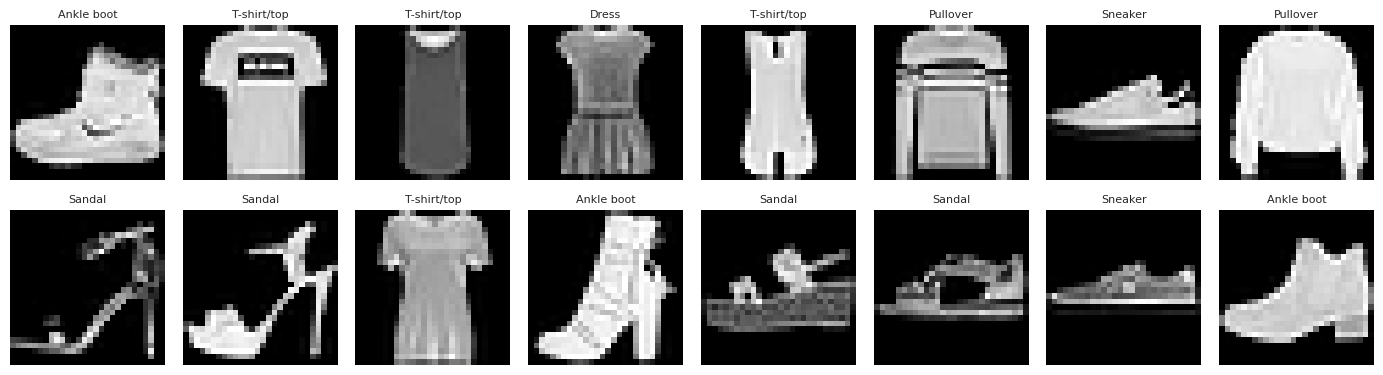

In [2]:
tf = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.2860,), (0.3530,))])
train_full = datasets.FashionMNIST('data', train=True, download=True, transform=tf)
test_set = datasets.FashionMNIST('data', train=False, download=True, transform=tf)      # locked until Day 3
train_set, val_set = random_split(train_full, [55000, 5000], generator=torch.Generator().manual_seed(0))
classes = train_full.classes
print('Train:', len(train_set), '| Validation:', len(val_set), '| Test (locked):', len(test_set))

BATCH = 128
train_dl = DataLoader(train_set, batch_size=BATCH, shuffle=True, num_workers=2)
val_dl = DataLoader(val_set, batch_size=512, num_workers=2)
xb, yb = next(iter(train_dl)); print('One batch:', xb.shape, yb.shape, '(batch, channels, height, width)')

fig, ax = plt.subplots(2, 8, figsize=(14, 4))
for a, i in zip(ax.ravel(), range(16)):
    img, lab = train_full[i]; a.imshow(img.squeeze() * 0.3530 + 0.2860, cmap='gray'); a.set_title(classes[lab], fontsize=8); a.axis('off')
plt.tight_layout(); plt.show()

## 2. Training helpers (same five-line loop as Phase 1, plus `.to(device)`)
The model and every batch must be moved to the same device (GPU). Everything else is unchanged.

In [3]:
loss_fn = nn.CrossEntropyLoss()           # 10 classes: logits in, class numbers as targets, softmax inside

def evaluate(model, dl):
    model.eval(); tot_loss = correct = n = 0
    with torch.no_grad():
        for xb, yb in dl:
            xb, yb = xb.to(device), yb.to(device); out = model(xb)
            tot_loss += loss_fn(out, yb).item() * len(yb); correct += (out.argmax(1) == yb).sum().item(); n += len(yb)
    return tot_loss / n, correct / n

def train(model, epochs=8, lr=1e-3):
    model.to(device); opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist = {'loss': [], 'val_loss': [], 'val_acc': [], 'time': []}
    for ep in range(epochs):
        t0 = time.time(); model.train(); run = n = 0
        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad(); loss = loss_fn(model(xb), yb); loss.backward(); opt.step()
            run += loss.item() * len(yb); n += len(yb)
        vl, va = evaluate(model, val_dl)
        for k, v in zip(hist, (run / n, vl, va, time.time() - t0)): hist[k].append(v)
        print(f'epoch {ep + 1:2d}/{epochs}  train loss {run / n:.3f}  val loss {vl:.3f}  val acc {va:.3f}  ({time.time() - t0:.1f}s)')
    return hist

n_params = lambda m: sum(p.numel() for p in m.parameters())
EPOCHS = 8

## 3. Baseline: the MLP from Phase 1
The MLP **flattens** the image into 784 numbers, so it throws away the 2D structure.

In [4]:
mlp = nn.Sequential(nn.Flatten(), nn.Linear(784, 256), nn.ReLU(), nn.Linear(256, 128), nn.ReLU(), nn.Linear(128, 10))
print('MLP parameters:', f'{n_params(mlp):,}')
h_mlp = train(mlp, epochs=EPOCHS)

MLP parameters: 235,146
epoch  1/8  train loss 0.493  val loss 0.375  val acc 0.860  (12.0s)
epoch  2/8  train loss 0.356  val loss 0.341  val acc 0.876  (11.7s)
epoch  3/8  train loss 0.314  val loss 0.317  val acc 0.884  (11.6s)
epoch  4/8  train loss 0.288  val loss 0.309  val acc 0.884  (12.0s)
epoch  5/8  train loss 0.272  val loss 0.333  val acc 0.874  (11.4s)
epoch  6/8  train loss 0.255  val loss 0.308  val acc 0.885  (10.5s)
epoch  7/8  train loss 0.240  val loss 0.303  val acc 0.890  (11.2s)
epoch  8/8  train loss 0.226  val loss 0.308  val acc 0.889  (11.6s)


## 4. A CNN
Structure: **[Conv -> ReLU -> MaxPool] x 2, then flatten, then a dense layer, then 10 outputs.**
- `nn.Conv2d(in_channels, out_channels, kernel_size, padding)`: `out_channels` is the **number of filters**.
- `nn.MaxPool2d(2)`: halves the height and width.
- `nn.Flatten()`: turns the feature maps into one vector for the dense layers.

The most common bug is a wrong shape at the first dense layer, so we **trace the shapes** with a dummy image first.

In [5]:
cnn = nn.Sequential(
    nn.Conv2d(1, 16, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),      # (1,28,28) -> (16,28,28) -> (16,14,14)
    nn.Conv2d(16, 32, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),     # -> (32,14,14) -> (32,7,7)
    nn.Flatten(),                                                                # -> 32*7*7 = 1568
    nn.Linear(32 * 7 * 7, 64), nn.ReLU(),
    nn.Linear(64, 10))

x = torch.zeros(1, 1, 28, 28)
for layer in cnn:
    x = layer(x); print(f'{layer.__class__.__name__:10s} -> output shape {tuple(x.shape)}')
print('\nCNN parameters:', f'{n_params(cnn):,}', '| MLP parameters:', f'{n_params(mlp):,}')

Conv2d     -> output shape (1, 16, 28, 28)
ReLU       -> output shape (1, 16, 28, 28)
MaxPool2d  -> output shape (1, 16, 14, 14)
Conv2d     -> output shape (1, 32, 14, 14)
ReLU       -> output shape (1, 32, 14, 14)
MaxPool2d  -> output shape (1, 32, 7, 7)
Flatten    -> output shape (1, 1568)
Linear     -> output shape (1, 64)
ReLU       -> output shape (1, 64)
Linear     -> output shape (1, 10)

CNN parameters: 105,866 | MLP parameters: 235,146


**Check with the formula from Day 1:** a 3x3 filter with padding 1 and stride 1 keeps 28x28, and each 2x2 max pool halves it: 28 -> 14 -> 7. So the flattened size is 32 x 7 x 7 = 1568.

In [6]:
h_cnn = train(cnn, epochs=EPOCHS)

epoch  1/8  train loss 0.531  val loss 0.379  val acc 0.866  (13.2s)
epoch  2/8  train loss 0.341  val loss 0.315  val acc 0.890  (11.7s)
epoch  3/8  train loss 0.293  val loss 0.300  val acc 0.895  (11.6s)
epoch  4/8  train loss 0.268  val loss 0.273  val acc 0.899  (11.7s)
epoch  5/8  train loss 0.244  val loss 0.258  val acc 0.905  (11.7s)
epoch  6/8  train loss 0.226  val loss 0.261  val acc 0.901  (11.3s)
epoch  7/8  train loss 0.212  val loss 0.244  val acc 0.911  (10.8s)
epoch  8/8  train loss 0.199  val loss 0.226  val acc 0.918  (11.5s)


## 5. Comparison on the validation set

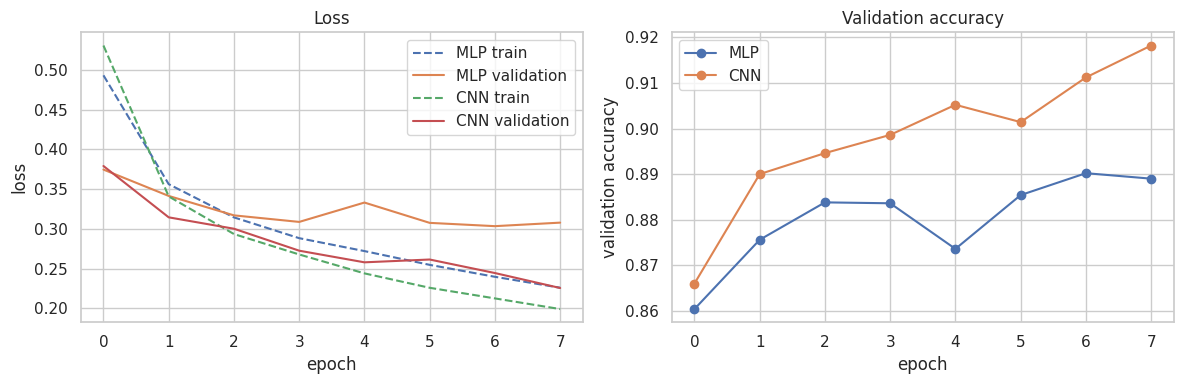

,parameters,best val acc,final val acc,final val loss,seconds / epoch
MLP,235146.0,0.890,0.889,0.308,11.497
CNN,105866.0,0.918,0.918,0.226,11.690


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for name, h in [('MLP', h_mlp), ('CNN', h_cnn)]:
    ax[0].plot(h['loss'], '--', label=f'{name} train'); ax[0].plot(h['val_loss'], label=f'{name} validation'); ax[1].plot(h['val_acc'], 'o-', label=name)
ax[0].set(xlabel='epoch', ylabel='loss', title='Loss'); ax[1].set(xlabel='epoch', ylabel='validation accuracy', title='Validation accuracy'); ax[0].legend(); ax[1].legend()
plt.tight_layout(); plt.show()

pd.DataFrame({'MLP': {'parameters': n_params(mlp), 'best val acc': max(h_mlp['val_acc']), 'final val acc': h_mlp['val_acc'][-1], 'final val loss': h_mlp['val_loss'][-1], 'seconds / epoch': np.mean(h_mlp['time'])},
              'CNN': {'parameters': n_params(cnn), 'best val acc': max(h_cnn['val_acc']), 'final val acc': h_cnn['val_acc'][-1], 'final val loss': h_cnn['val_loss'][-1], 'seconds / epoch': np.mean(h_cnn['time'])}}).T.round(3)

## 6. Look at the predictions
Accuracy hides what the model gets wrong. Show some validation images with the CNN's predictions, wrong ones in red.

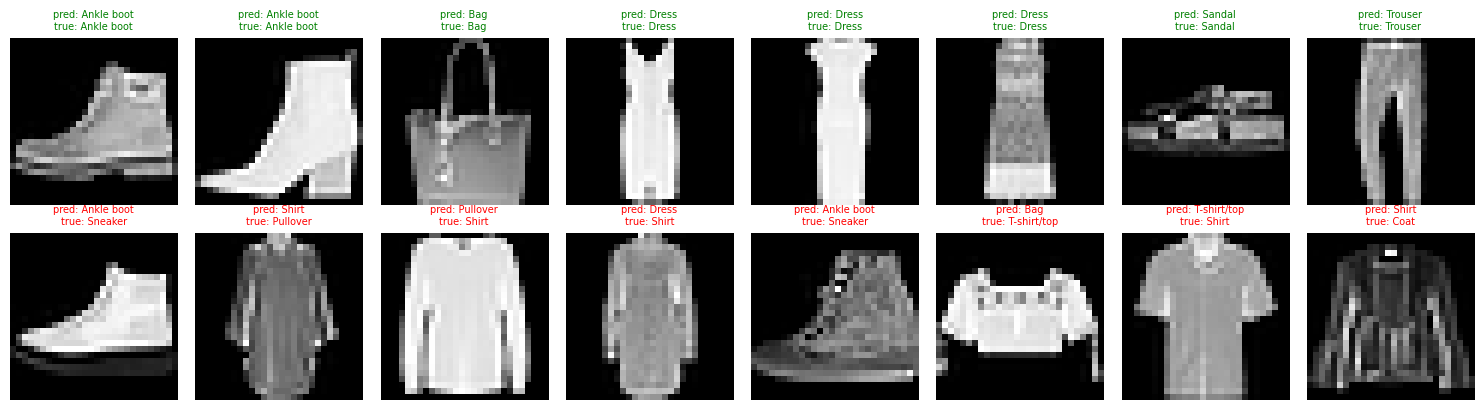

This batch: 0.920 accuracy; 8 wrong shown


In [8]:
cnn.eval(); xb, yb = next(iter(val_dl))
with torch.no_grad(): pred = cnn(xb.to(device)).argmax(1).cpu()
wrong = (pred != yb).nonzero().ravel()[:8]; right = (pred == yb).nonzero().ravel()[:8]
fig, ax = plt.subplots(2, 8, figsize=(15, 4.2))
for row, idxs, title in [(0, right, 'correct'), (1, wrong, 'WRONG')]:
    for a, i in zip(ax[row], idxs):
        a.imshow(xb[i].squeeze() * 0.3530 + 0.2860, cmap='gray'); a.axis('off')
        a.set_title(f'pred: {classes[pred[i]]}\ntrue: {classes[yb[i]]}', fontsize=7, color='green' if row == 0 else 'red')
plt.tight_layout(); plt.show()
print(f'This batch: {(pred == yb).float().mean():.3f} accuracy; {len(wrong)} wrong shown')